In [1]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import chemparse
import numpy as np

In [8]:
font = {"family" : "normal",
    "size" : 22}

for key, value in font.items():
    plt.rcParams.update({"font." + key : value})

In [3]:
fp = "Data/br08001.json"
with open(fp) as json_file:
  br_json = json.load(json_file)

classes = []
cpd_class = {}
for key1 in br_json["children"]:
  classes.append(key1["name"])
  for key2 in key1["children"]:
    for key3 in key2["children"]:
      for cpd in key3["children"]:
        cpd_class[cpd["name"][:6]] = key1["name"]
        #print(cpd["name"][:6] + " " + key1["name"])

print(cpd_class)

{'C00058': 'Organic acids', 'C00033': 'Organic acids', 'C00163': 'Organic acids', 'C00246': 'Lipids', 'C00803': 'Organic acids', 'C01585': 'Lipids', 'C17714': 'Organic acids', 'C06423': 'Lipids', 'C00209': 'Organic acids', 'C00383': 'Organic acids', 'C00042': 'Organic acids', 'C00489': 'Organic acids', 'C06104': 'Organic acids', 'C02656': 'Organic acids', 'C08278': 'Organic acids', 'C00158': 'Organic acids', 'C00311': 'Organic acids', 'C00417': 'Organic acids', 'C02341': 'Organic acids', 'C00048': 'Organic acids', 'C00022': 'Organic acids', 'C00109': 'Organic acids', 'C06255': 'Organic acids', 'C00902': 'Organic acids', 'C00036': 'Organic acids', 'C00026': 'Organic acids', 'C00322': 'Organic acids', 'C16588': 'Organic acids', 'C16589': 'Organic acids', 'C00141': 'Organic acids', 'C00233': 'Organic acids', 'C00671': 'Organic acids', 'C00222': 'Organic acids', 'C00164': 'Organic acids', 'C00232': 'Organic acids', 'C00186': 'Organic acids', 'C00149': 'Organic acids', 'C01013': 'Organic ac

In [4]:
fp = "Data/cpd_appearence_data.csv"
df = pd.read_csv(fp)
df.head()

,Compound,Formula,Chiral_Centers,Mol_Weight,Timestep_Appear,Pathways,Size_When_Added
0,C21282,C7H12O6,4,192.1666,12,[],608
1,C16470,C28H46N7O17P3S,5,877.6878,27,['00281'],4287
2,C21573,C15H27NO,0,237.3810,17,"['01130', '00333']",1643
3,C16320,C18H28O3,0,292.4131,27,"['01110', '00592']",4287
4,C16578,C23H27NO9,10,461.4618,29,['00982'],4543


In [5]:
#Find compounds with classifications under BRITE that appear in the expansion
overlap = {}

for cpd in df["Compound"]:
  if cpd in cpd_class.keys():
    overlap[cpd] = cpd_class[cpd]
  else:
    overlap[cpd] = ""

df["Labels"] = df["Compound"].map(overlap)

for c in classes:
  #Make sub-dataframe for each class
  sub_df = df[df["Labels"] == c]
  chiral_cpds = 0
  for item, row in sub_df.iterrows():
    if row["Chiral_Centers"] > 0:
      chiral_cpds += 1
  if len(sub_df) != 0:
    print("Chirality of", c, "is:", float(chiral_cpds)/len(sub_df))

heavy_atoms = []
heavy_atoms_2 = []
#Find number of heavy (non-H) atoms for each cpd
for f in df["Formula"]:
  try: #Account for nans
    formula = chemparse.parse_formula(f)
    sum = 0
    for atom, count in formula.items():
      if atom != "H":
        sum += count
    #Bins of 20 (10 bins) & 40 (5 bins) heavy atoms
    if int(sum/40) == 0:
      heavy_atoms.append("0 - 20th")
    elif int(sum/40) == 1:
      heavy_atoms.append("21 - 40th")
    elif int(sum/40) == 2:
      heavy_atoms.append("41 - 60th")
    elif int(sum/40) == 3:
      heavy_atoms.append("61 - 80th")
    else:
      heavy_atoms.append("81 - 100th")

  except:
    heavy_atoms.append("0 - 20th")

df["Heavy Atoms"] = heavy_atoms

df = df.rename(columns={"Timestep_Appear": "Expansion Step", "Chiral_Centers": "Chiral Centers"})

df.sort_values(by="Heavy Atoms")


Chirality of Organic acids is: 0.125
Chirality of Lipids is: 0.5227272727272727
Chirality of Carbohydrates is: 0.9682539682539683
Chirality of Nucleic acids is: 0.8936170212765957
Chirality of Peptides is: 0.8431372549019608
Chirality of Vitamins and Cofactors is: 0.6451612903225806
Chirality of Hormones and transmitters is: 0.4166666666666667
Chirality of Antibiotics is: 1.0


,Compound,Formula,Chiral Centers,Mol_Weight,Expansion Step,Pathways,Size_When_Added,Labels,Heavy Atoms
0,C21282,C7H12O6,4,192.1666,12,[],608,,0 - 20th
3124,C00705,C9H15N3O10P2,3,387.1770,17,['00240'],1643,Nucleic acids,0 - 20th
3125,C11821,C5H4N4O4,0,184.1097,8,"['01120', '00230']",170,,0 - 20th
3126,C03526,NaN,0,0.0000,19,[],2252,,0 - 20th
3127,C21618,C4H6O5,1,134.0874,16,[],1425,,0 - 20th
...,...,...,...,...,...,...,...,...,...
4322,C19890,C115H211N3O42P2,28,2369.8483,31,['00540'],4662,,81 - 100th
4711,C21463,C114H214N4O45P4,24,2484.8138,32,['00540'],4714,,81 - 100th
2705,C06042,C92H201O140P25R2,36,0.0000,29,['00561'],4543,,81 - 100th
45,C21173,C112H208N3O42P3,24,2361.7661,31,['00540'],4662,,81 - 100th


findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


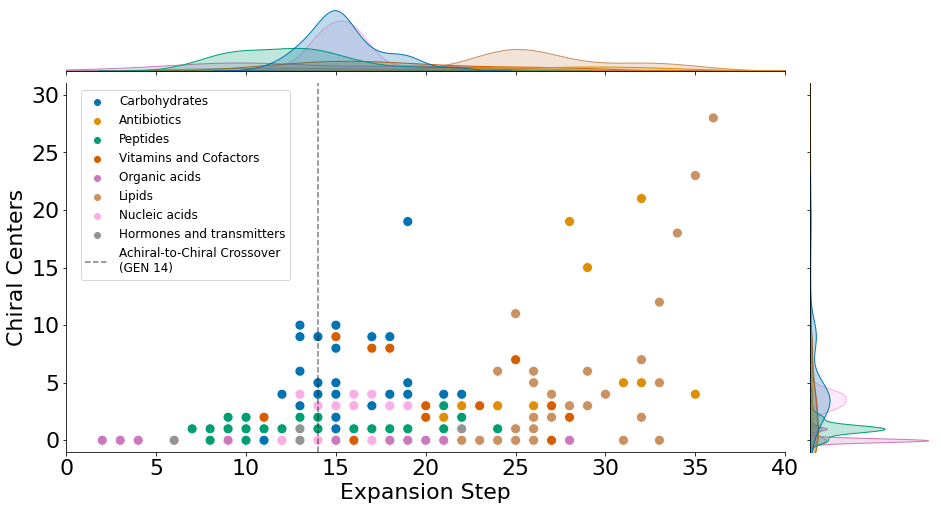

In [8]:
g = sns.jointplot(data=df[df["Labels"] != ""], x="Expansion Step", y="Chiral Centers", 
                  hue="Labels", palette="colorblind", ylim=(-1,31), xlim=(0,40), s=100)

g.figure.set_size_inches((16, 8))

# for ax in (kdeplot.ax_joint, kdeplot.ax_marg_x):
#     ax.axvline(0, color='crimson', ls='--', lw=3)
g.ax_joint.axvline(x=14, color="k", alpha=0.5, linestyle="--", label="Achiral-to-Chiral Crossover\n(GEN 14)")

#plt.legend(bbox_to_anchor=(1,1), prop={"size":14})
g.ax_joint.legend(bbox_to_anchor=(0.32,0.45), prop={"size":12})

plt.savefig("fig3.svg", format="svg")

0.16734804009127285 -0.5233940152112948


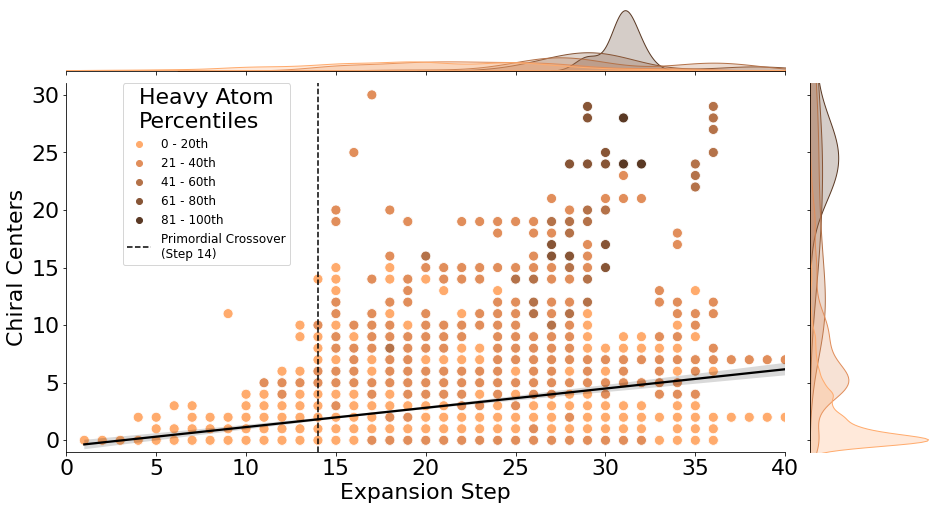

In [17]:
#Plotting all cpds, (eventually) coloring by num heavy atoms
sns.set_palette(sns.color_palette("copper_r"))
g = sns.jointplot(data=df.sort_values(by="Heavy Atoms"), x="Expansion Step", y="Chiral Centers", 
                  hue="Heavy Atoms", #palette=sns.color_palette("Greens"), 
                  ylim=(-1,31), xlim=(0,40), s=100, marginal_kws={'common_norm':False})
h = sns.regplot(x="Expansion Step", y="Chiral Centers", data=df, ax=g.ax_joint, 
                scatter=False, color="k")

m,b = np.polyfit(df["Expansion Step"], df["Chiral Centers"], 1)
print(m, b)

g.figure.set_size_inches((16, 8))

# for ax in (kdeplot.ax_joint, kdeplot.ax_marg_x):
#     ax.axvline(0, color='crimson', ls='--', lw=3)
g.ax_joint.axvline(x=14, color="k", linestyle="--", label="Primordial Crossover\n(Step 14)")

#plt.legend(bbox_to_anchor=(1,1), prop={"size":14})
g.ax_joint.legend(title="Heavy Atom\nPercentiles", bbox_to_anchor=(0.32,0.49), prop={"size":12})

plt.savefig("fig3b.png", format="png")

In [ ]:
#Plotting all cpds, (eventually) coloring by num heavy atoms
g = sns.jointplot(data=df, x="Expansion Timestep", y="Chiral Centers", 
                  hue="Heavy Atoms 2", palette="colorblind", ylim=(-1,31), xlim=(0,40), s=100)

g.figure.set_size_inches((16, 8))

# for ax in (kdeplot.ax_joint, kdeplot.ax_marg_x):
#     ax.axvline(0, color='crimson', ls='--', lw=3)
g.ax_joint.axvline(x=14, color="k", alpha=0.5, linestyle="--", label="Achiral-to-Chiral Crossover\n(GEN 14)")

#plt.legend(bbox_to_anchor=(1,1), prop={"size":14})
g.ax_joint.legend(bbox_to_anchor=(0.32,0.45), prop={"size":12})

plt.savefig("fig3.svg", format="svg")
plt.savefig("fig3.png", format="png")


### Degrees / Chirality plot

In [6]:
degree_df = pd.read_csv("Data/undirected_cp_cp_degrees_from_reaction_edges.csv")

df = pd.merge(df, degree_df, left_on=["Compound"], right_on=["Cpd"])
print(df)

     Compound         Formula  Chiral Centers  Mol_Weight  Expansion Step  \
0      C21282         C7H12O6               4    192.1666              12   
1      C16470  C28H46N7O17P3S               5    877.6878              27   
2      C21573        C15H27NO               0    237.3810              17   
3      C16320        C18H28O3               0    292.4131              27   
4      C16578       C23H27NO9              10    461.4618              29   
...       ...             ...             ...         ...             ...   
4874   C19699    C20H9Cl2N3O2               0    394.2104              30   
4875   C11501      C10H11N5O5               4    281.2248              15   
4876   C20367         C7H5NO7               0    215.1171              18   
4877   C20854        C19H30O5               7    338.4385              23   
4878   C09844         C10H18O               0    154.2493              25   

                Pathways  Size_When_Added Labels Heavy Atoms     Cpd  Degre

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator


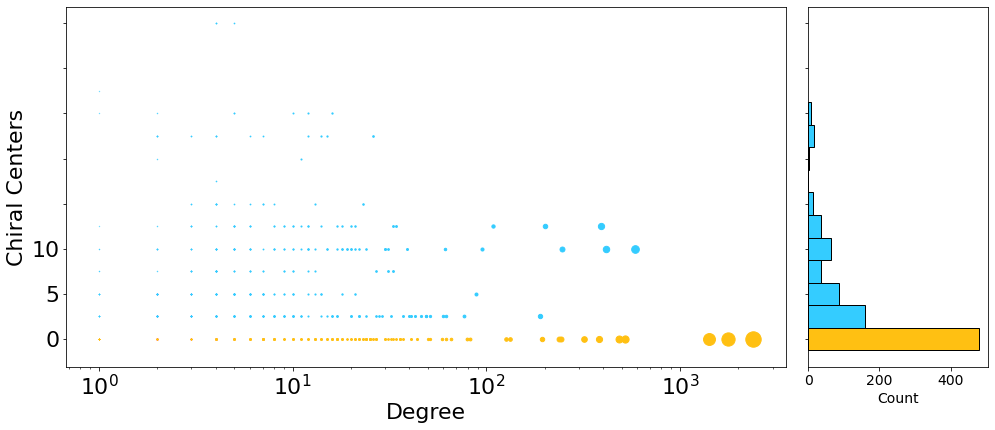

In [16]:
def scatter_hist(x, y, ax, ax_histy, c):
    achiral_color = "#FFC012"
    chiral_color = "#34CCFF"

    ax_histy.tick_params(axis="y", labelleft=False)

    #Plot by chiral/achiral color, and size by degree
    for i in range(len(x)):
        if y[i] == 0:
            ax.scatter(x[i], y[i], color=achiral_color, s=x[i]/10)
        else:
            ax.scatter(x[i], y[i], color=chiral_color, s=x[i]/10)

    #Set bins to middle of chiral center y-values to line up across axes
    bins = np.arange(-0.5,11.5,1)
    cnts, values, bars = ax_histy.hist(np.array(y)-0.5, orientation='horizontal', color=c, bins=bins, edgecolor="k")

    #Make sure labels are smaller on histogram than scatter plot
    ax_histy.set_xlabel("Count", fontsize=14)
    ax_histy.tick_params(axis='both', which='major', labelsize=14)

    #Change color of histogram bars
    for i, (cnt, value, bar) in enumerate(zip(cnts, values, bars)):
        if i == 0:
            bar.set_facecolor(achiral_color)
        else:
            bar.set_facecolor(chiral_color)


#Only include up to expansion step 14 to match network
sub_df = df[df["Expansion Step"] <= 14]

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)
ax = fig.add_subplot(gs[1, 0])
#ax_histx = fig.add_subplot(gs[0, 0], sharex=ax) #No top histogram
ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
scatter_hist(list(sub_df["Degree"]), list(sub_df["Chiral Centers"]), ax, ax_histy, "k")

ax.set_yticklabels(["", "0", "5", "10"])

ax.set_xscale("log")

ax.set_xlabel("Degree")
ax.set_ylabel("Chiral Centers")

plt.savefig("fig3c.png", format="png")

<AxesSubplot:>

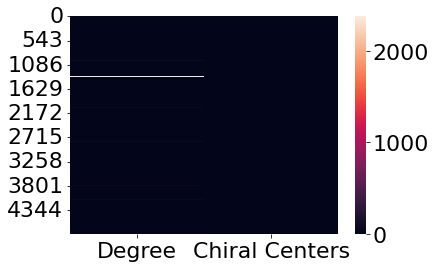

In [27]:
import seaborn as sns

sns.heatmap(df[["Degree", "Chiral Centers"]])

### Network expansion figure
* Netwulf: ``pip install netwulf`` [source](github.com/benmaier/netwulf), [citation](doi.org/10.21105/joss.01425). also requires ``simplejson>=3.0``

### Setup: 
* Import packages
* Declare convenience functions
* Import datasets
* Delete intermediate variables

In [1]:
# PACKAGES
import json
import pandas as pd
import numpy as np
import networkx as nx
import netwulf as nw
from netgraph import Graph, get_multipartite_layout

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, to_hex, BoundaryNorm

# CONVENIENCE FUNCTIONS
def gna(G, attr): return nx.get_node_attributes(G, attr)
def gea(G, attr): return nx.get_edge_attributes(G, attr)
def invD2S(d): return(pd.Series({j:i for i,j in d.items()}))

def colorize_Series(S, cmap='cet_CET_C6s'):
    # S should be list-like, or a dict, or a series.... of numbers.
    color_map = matplotlib.colormaps[cmap]
    def float_norm(x): return(Normalize(vmin=x.min(), vmax=x.max()))
    def boundary_norm(x): return(BoundaryNorm(boundaries=list(range(x.min(), x.max()+1, 1)), ncolors=color_map.N))
    if type(S)!=pd.Series:
        S = pd.Series(S)
    if S.dtype==pd.Float64Dtype():
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
    elif S.dtype==pd.Int64Dtype():
        c_ser = pd.Series(map(tuple, color_map(boundary_norm(S)(list(S.values)))), index=S.index)
    else:
        S = pd.Series(S.factorize()[0])/(pd.Series(S.factorize()[0]).max())
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
    return(c_ser)

max_gen = 14
gen_color = 'Greys'

# DATA SOURCES
# Network expansion generations
gens = pd.DataFrame(json.load(open('Data/primordial.dat0.json','r'))['generations']).T.iloc[:,2:]
gens.index = gens.index.astype(int)
gens.sort_index(inplace=True)

i = invD2S(pd.concat(objs = [gens['compounds_new'].reset_index(drop=True), gens['reactions_new']] ).explode().dropna()) + 1 # steps
j = pd.read_csv('Data/chiral_labels.csv', index_col='Cpd', usecols=['Cpd','Chiral_Centers']).iloc[:,0] # chiral centers
k = pd.read_csv('Data/compound_first_names_KEGGv110.0.csv.zip', index_col=0, header=0)['1'] # node names

attributes = (i-1).to_frame(name='gen').assign(n_chiral_centers=j, is_chiral=j>0, name=k).convert_dtypes() #combined dataframe of attributes
attributes['is_chiral_color'] = attributes['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF")
attributes['gen_color'] = colorize_Series(attributes['gen'], cmap=gen_color).apply(to_hex)

reactions = pd.DataFrame(json.load(open('Data/reaction_edges.json'))).apply(lambda x: x.apply(set))
edges = (reactions.loc[reactions.index.intersection(attributes.index)]
         .rename(columns={'substrates':'s','products':'p'}).explode('s').explode('p').reset_index(names='r').query('s!=p'))

del i; del j; del k; attributes.head()


,gen,n_chiral_centers,is_chiral,name,is_chiral_color,gen_color
C00014,0,0,False,Ammonia,#FFC012,#ffffff
C00011,0,0,False,CO2,#FFC012,#ffffff
C00080,0,0,False,H+,#FFC012,#ffffff
C00009,0,0,False,Orthophosphate,#FFC012,#ffffff
C00059,0,0,False,Sulfate,#FFC012,#ffffff


Use expansion generation-members to infer reaction directionality WRT expansion.

In [2]:
edges = edges.join(edges.apply(lambda x: x.map(attributes['gen'])).add_suffix('_gen').dropna(), how='right') # consider only reactions and compounds in the expansion
edges = edges.assign(new_compound = lambda x: (x.s_gen==x.r_gen) + (x.p_gen==x.r_gen), # reaction enabled a new compound
             immediate_precursor = lambda x: ((x.p_gen-x.s_gen).abs()==1) * (x.new_compound), # one compound is other's most recent precursor
             core_reaction = lambda x: x.r.isin(x.loc[x.new_compound, 'r'].unique())) # reaction thus enables expansion
edges['rev'] = edges['r'].map(edges.query('core_reaction').groupby(by='r')[['s_gen','p_gen']].max().T.idxmax().map({'s_gen':True,'p_gen':False}))
edges = edges.assign(source = lambda x: x.rev * x.p + (x.rev==False) * x.s,
                     target = lambda x: x.rev * x.s + (x.rev==False) * x.p).reset_index(drop=True).sort_values(by='r_gen')
edges.tail()

,r,p,s,r_gen,p_gen,s_gen,new_compound,immediate_precursor,core_reaction,rev,source,target
13503,R09411,C19589,C19588,43,43,42,True,True,True,False,C19588,C19589
13505,R09413,C19592,C19589,44,44,43,True,True,True,False,C19589,C19592
16668,R09412,C19591,C19589,44,44,43,True,True,True,False,C19589,C19591
16654,R09414,C19590,C19591,45,45,44,True,True,True,False,C19591,C19590
16657,R09415,C19590,C19592,45,45,44,True,True,True,False,C19592,C19590


In [17]:
"""
# For comparison... calculate compound degree distribution for all of KEGG vs compounds in the selected stage of expansion.
print(len(edges.r.unique()),  ' unique reactions')
G_kegg = nx.from_pandas_edgelist(edges, source='s', target='p', create_using=nx.Graph()) # NOT directed, NOT multigraph
kegg_degrees = pd.Series(dict(G_kegg.degree()), name='Degree').sort_values(ascending=False)
kegg_degrees.to_csv('undirected_cp_cp_degrees_from_reaction_edges.csv.zip', compression='zip', encoding='utf-8')
kegg_degrees.apply(np.log10).plot.hist(bins=20, xlabel='log10(Degree)', alpha=0.5, 
    title='KEGG Compound-Compound Degree Distribution')
kegg_degrees.loc[attributes.dropna(subset='name').index].apply(np.log10).plot.hist(alpha=0.5, bins=20)
plt.show()

del G_kegg
"""
print()

ID when compounds are first connected; generate edge lists accordingly.

In [3]:
edges = edges.assign(A=edges[['s','p']].T.max(), B=edges[['s','p']].T.min()) # because A->B and B->A reflect the same edge
edge_lists = {'infilled': edges.groupby(by=['A','B'], as_index=False)['r_gen'].min().rename(columns={'A':'source','B':'target'})}
edges.drop(columns=['A','B'], inplace=True)
fuse_edges = lambda x: x.groupby(by=['source','target'], as_index=False)['r_gen'].min()
edge_lists.update({'core': fuse_edges(edges[edges['core_reaction']]), 'precursor': fuse_edges(edges[edges['immediate_precursor']])})

Generate network state at the transition generation (from majority-achiral to majority-chiral).

In [4]:
generation = max_gen
networks = dict()
for i,j in edge_lists.items(): 
    print(i, len(j[j['r_gen']<=generation].index), 'edges of', len(j.index), 'imported')
    networks[i] = nx.from_pandas_edgelist(j[j['r_gen']<=generation], create_using=nx.DiGraph(), edge_attr=True)
    [nx.set_node_attributes(networks[i], attributes[k].to_dict(), k) for k in attributes.columns]
networks['infilled'] = networks['infilled'].to_undirected()

print(pd.Series({i: [networks[i].number_of_edges(), type(j)] for i,j in networks.items()}))
print('\nfraction chiral:', pd.Series(gna(networks['infilled'], 'is_chiral')).mean())

infilled 3699 edges of 18065 imported
core 3481 edges of 17628 imported
precursor 1394 edges of 5525 imported
infilled        [3699, <class 'networkx.classes.graph.Graph'>]
core         [3481, <class 'networkx.classes.digraph.DiGrap...
precursor    [1394, <class 'networkx.classes.digraph.DiGrap...
dtype: object

fraction chiral: 0.5251736111111112


Calculate some informative metrics regarding each compound's importance to the expansion.

In [7]:
attributes = attributes.assign(infilled_degree = dict(networks['infilled'].degree()), #calculate overall degree
    core_out_degree = dict(networks['core'].out_degree()),  # calculate out-degree for all cpds
    precursor_out_degree = dict(networks['precursor'].out_degree()),  # and among immediate precursors
    core_out_degree_chiral = {n: attributes['is_chiral'].loc[networks['core'].successors(n)].sum() for n in networks['core'].nodes},
    precursor_out_degree_chiral = {n: attributes['is_chiral'].loc[networks['precursor'].successors(n)].sum() for n in networks['precursor'].nodes})

for k in ['infilled_degree', 'core_out_degree', 'precursor_out_degree', 'core_out_degree_chiral', 'precursor_out_degree_chiral']:
    attributes[k] = attributes[k].fillna(0).astype(int)
    for n in networks.keys():
        nx.set_node_attributes(networks[n], dict(attributes[k]), k)

attributes.head()

,gen,n_chiral_centers,is_chiral,name,is_chiral_color,gen_color,infilled_degree,core_out_degree,precursor_out_degree,core_out_degree_chiral,precursor_out_degree_chiral
C00014,0,0,False,Ammonia,#FFC012,#ffffff,156,115,7,45,0
C00011,0,0,False,CO2,#FFC012,#ffffff,146,68,10,19,0
C00080,0,0,False,H+,#FFC012,#ffffff,32,19,0,2,0
C00009,0,0,False,Orthophosphate,#FFC012,#ffffff,171,83,1,47,0
C00059,0,0,False,Sulfate,#FFC012,#ffffff,19,12,0,6,0


Visualize network at this stage of the expansion.

<Figure size 720x864 with 0 Axes>

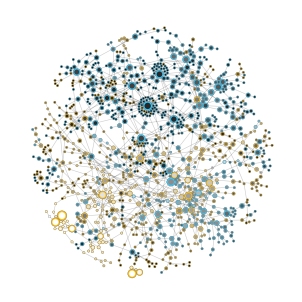

In [8]:
folder = 'fig3_network_components/'

size_nodes_by = 'core_out_degree_chiral' #or precursor_out_degree, or infilled_degree, etc. etc. 
max_node_size = 25

G = networks['precursor'].copy()
fig = plt.figure(figsize=(10,12), layout='constrained')
node_sizes = pd.Series({i:(np.log2(j+2))**1.5 for i,j in gna(G, size_nodes_by).items()})
nx.set_node_attributes(G, node_sizes, 'size')
nx.set_node_attributes(G, gna(G, 'is_chiral_color'), 'group')
stylized_network, config = nw.visualize(G, config={'node_label_color': '#000000', 'node_gravity': 0.15, 
                                'link_alpha': 0.2, 'link_color': '#000000', 'zoom': 0.75, 'node_charge': -53,
                                'scale_node_size_by_strength': False, 'node_size': max_node_size, 'link_distance':23})
fig, ax = nw.draw_netwulf(stylized_network)

a = stylized_network.copy()
a['nodeStrokeWidth'] = 0.0
for i in list(range(len(a['nodes']))):
    a['nodes'][i]['radius'] = a['nodes'][i]['radius'] * 0.7
    a['nodes'][i]['color'] = attributes['gen_color'].loc[a['nodes'][i]['id']]

nw.draw_netwulf(a, fig=fig, ax=ax, draw_links=False)
#plt.savefig(folder+'fig3_gen14_combined.svg', transparent=True)
plt.show()

Legends for generations, chirality, and chiral out-degree.

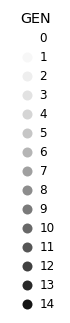

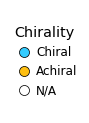

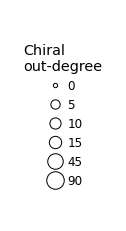

In [11]:
folder = 'fig3_network_components/'
fig, ax = plt.subplots(figsize=(1,5))
nodes = pd.DataFrame(a['nodes'])
gens_shown = pd.DataFrame({'gen': nodes['id'].map(attributes['gen']), 'color': nodes['color']}).drop_duplicates().sort_values(by='gen').set_index('gen')['color']
handles = [plt.Line2D([0], [0], marker='o', color='w', markeredgecolor='k', markeredgewidth=0, markerfacecolor=j, markersize=10, label=str(i)) for i,j in gens_shown.items()]
plt.legend(loc='center', frameon=False, handles=handles, fontsize='large', handletextpad=0.01, title='GEN', title_fontsize='x-large')
plt.axis('off')
#plt.savefig(folder+'fig3_gen14_legend_generation.svg')
plt.show()

fig, ax = plt.subplots(figsize=(1,2))
chiralities_shown = dict(zip(['Chiral', 'Achiral', 'N/A'],sorted(set(gna(G, 'group').values()))))
handles = [plt.Line2D([0], [0], marker='o', color='w', markeredgecolor='k', markeredgewidth=stylized_network['nodeStrokeWidth'],
                       markerfacecolor=j, markersize=10, label=str(i)) for i,j in chiralities_shown.items()]
plt.legend(loc='center', frameon=False, handles=handles, fontsize='large', handletextpad=0.01, title='Chirality', title_fontsize='x-large')
plt.axis('off')
#plt.savefig(folder+'fig3_gen14_legend_chirality.svg')
plt.show()

#k = attributes['core_out_degree_chiral'].apply(lambda x: ((x%5==0)+(x!=0))==2)
#attributes['core_out_degree_chiral'].loc[k].unique()

example_ids = ['C05359', 'C00094', 'C00065', 'C00037', 'C00014', 'C00001']
example_radii = pd.DataFrame(stylized_network['nodes']).query('id.isin(@example_ids)').set_index('id')['radius']
example_radii = example_radii.rename(attributes['core_out_degree_chiral']).sort_index()

fig, ax = plt.subplots(figsize=(2,4))
gens_shown = pd.DataFrame({'gen': nodes['id'].map(attributes['gen']), 'color': nodes['color']}).drop_duplicates().sort_values(by='gen').set_index('gen')['color']
handles = [plt.Line2D([0], [0], marker='o', color='w', markeredgecolor='k', markeredgewidth=1, markerfacecolor='w', markersize=2*j, label=str(i)) for i,j in example_radii.items()]
plt.legend(loc='center', frameon=False, handles=handles, fontsize='large', handletextpad=0.01, title='Chiral\nout-degree', title_fontsize='x-large')
plt.axis('off')
#plt.savefig(folder+'fig3_gen14_legend_chiraloutdegree.svg')
plt.show()


Show the connections between each compound and its last-arriving precursor.

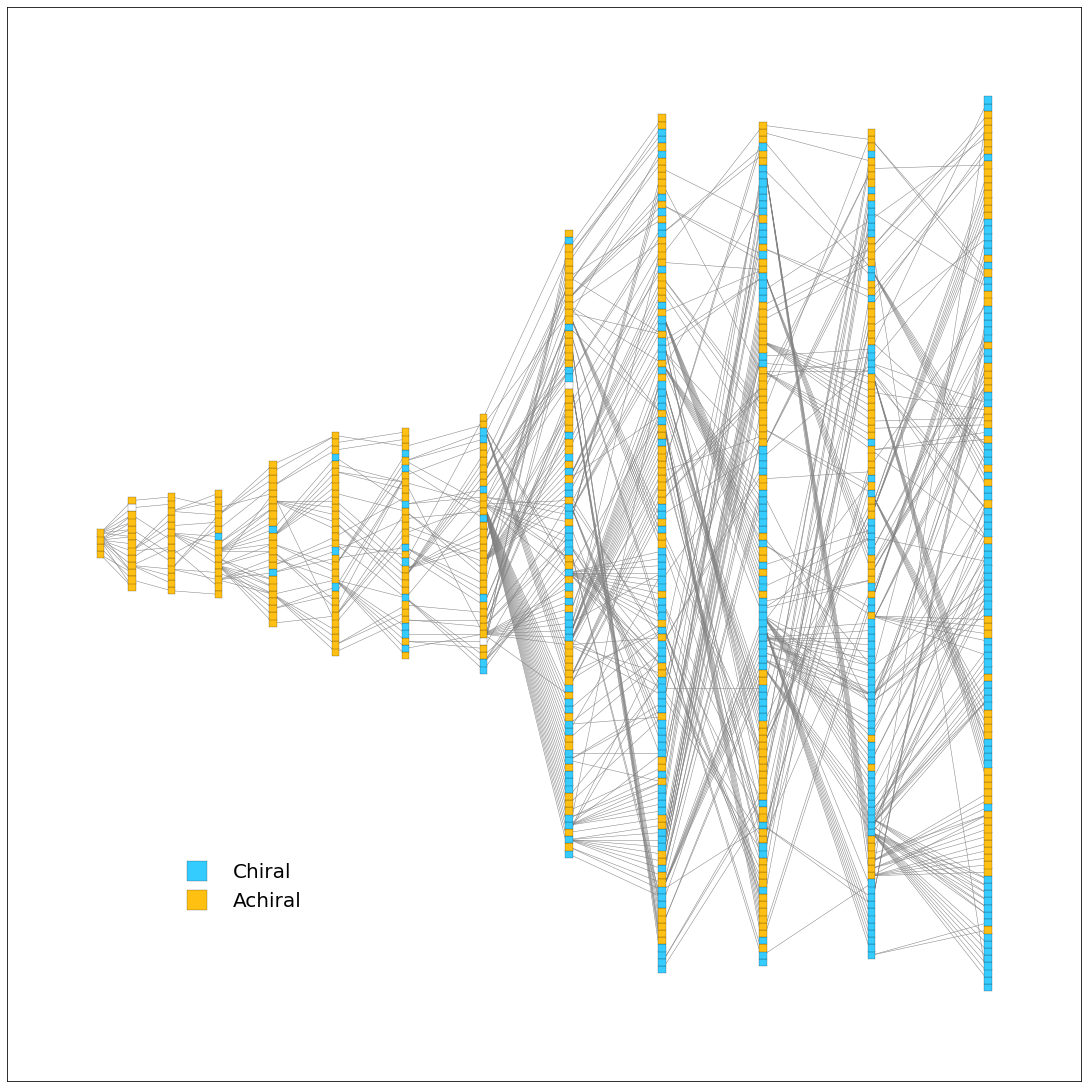

In [28]:
#attributes['test'] = (attributes['precursor_out_degree_chiral']/(attributes['is_chiral']-0.5)).filter(like='C').sort_values()
#sortby = ['is_chiral', 'test']
show = 'precursor'
rotate = False

G = networks[show]
layers = [list(i) for i in attributes.loc[list(G.nodes)].groupby(by='gen').groups.values()][:-1]
pos = get_multipartite_layout(edges=list(G.edges), layers=layers, reduce_edge_crossings=True)
for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2 # spread out later gens to reduce extreme angles 
if rotate: pos = {i:j[::-1] for i,j in pos.items()}

fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                  node_color=list(gna(G.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.5, arrows=False,
                  linewidths=0.2, node_size=55, node_shape='s', alpha=0.99,
                  with_labels=False)

plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('fig3_expansion_'+show+'_edges_minimal_crossings.svg', format='svg', facecolor='w', edgecolor='w')
plt.show()

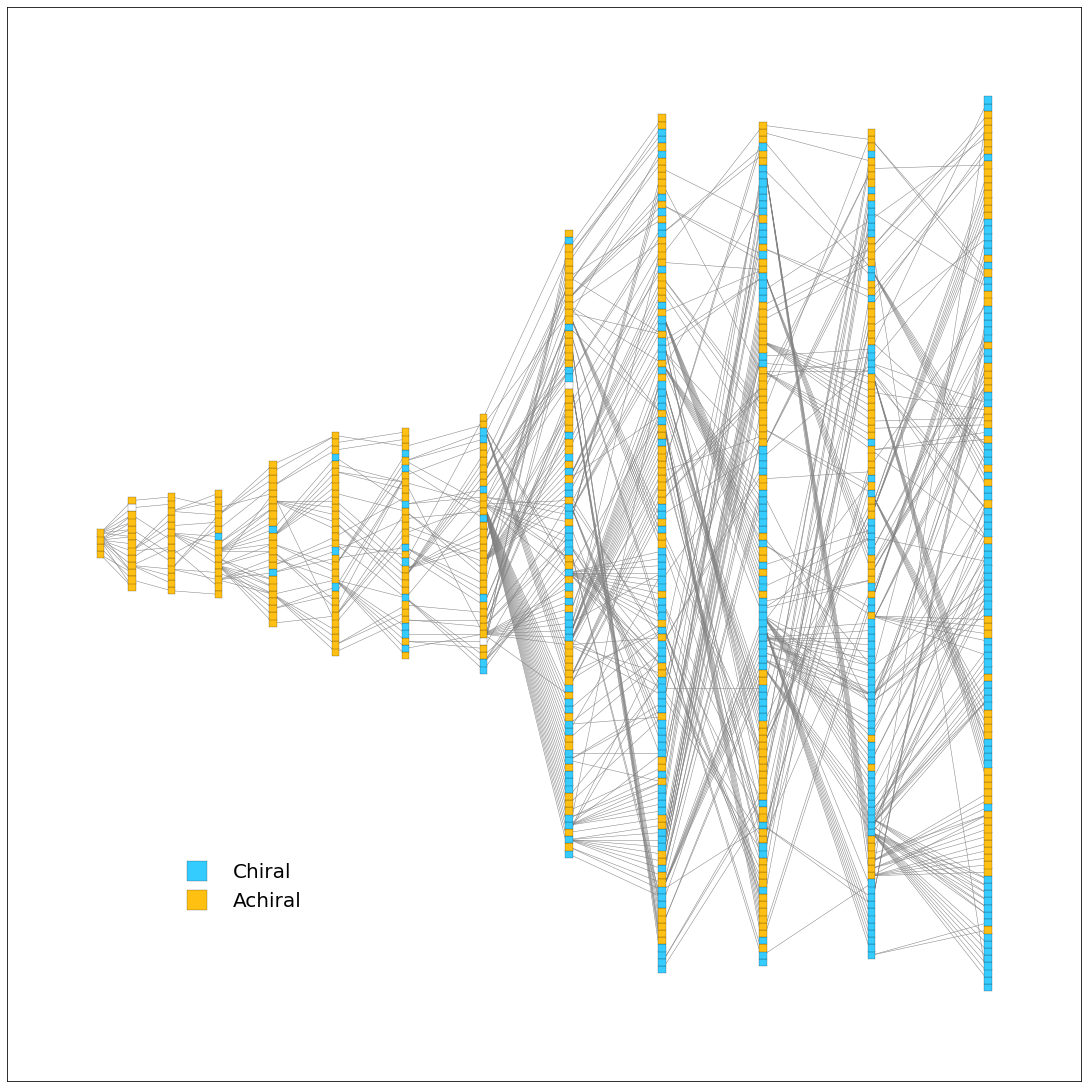

In [52]:
#attributes['test'] = (attributes['precursor_out_degree_chiral']/(attributes['is_chiral']-0.5)).filter(like='C').sort_values()
#sortby = ['is_chiral', 'test']
show = 'precursor'
rotate = False

G = networks[show]
layers = [list(i) for i in attributes.loc[list(G.nodes)].groupby(by='gen').groups.values()][:-1]
pos = get_multipartite_layout(edges=list(G.edges), layers=layers, reduce_edge_crossings=True)
for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2 # spread out later gens to reduce extreme angles 
if rotate: pos = {i:j[::-1] for i,j in pos.items()}

fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                  node_color=list(gna(G.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.5, arrows=False,
                  linewidths=0.2, node_size=55, node_shape='s', alpha=0.99,
                  with_labels=False)

plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('fig3_expansion_'+show+'_edges_minimal_crossings.svg', format='svg', facecolor='w', edgecolor='w')
plt.show()

In [36]:
attributes.query('gen<15').dropna(subset=['name']).to_csv('compound_names_and_attributes_up_to_gen14.csv', index=True, encoding='utf-8')

<ipython-input-36-802d1f243cd2>:1: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  attributes.query('gen<15').dropna(subset=['name']).to_csv('compound_names_and_attributes_up_to_gen14.csv', index=True, encoding='utf-8')


In [55]:
pd.DataFrame(pos).T.rename(columns={1:'y',0:'x'}).to_csv('Data/node_arrangement_layers.csv', index=True, encoding='utf-8')

,0,1
C00001,0.062500,0.492012
C00009,0.062500,0.497337
C00011,0.062500,0.502663
C00014,0.062500,0.507988
C01353,0.101908,0.468047
...,...,...
C14095,1.168062,0.806213
C16210,1.168062,0.811538
C16214,1.168062,0.816864
C19831,1.168062,0.822189


In [50]:
highlighted = ['C00014','C00013','C00037','C00065','C00049','C00111','C00166','C00031']
labels = attributes.loc[highlighted, 'name'].to_dict()

In [49]:
attributes.query('name=="D-Glucose"')


,gen,n_chiral_centers,is_chiral,name,is_chiral_color,gen_color,infilled_degree,core_out_degree,precursor_out_degree,core_out_degree_chiral,precursor_out_degree_chiral,test
C00031,11,4,True,D-Glucose,#34CCFF,#dadada,34,26,16,23,16,46.0


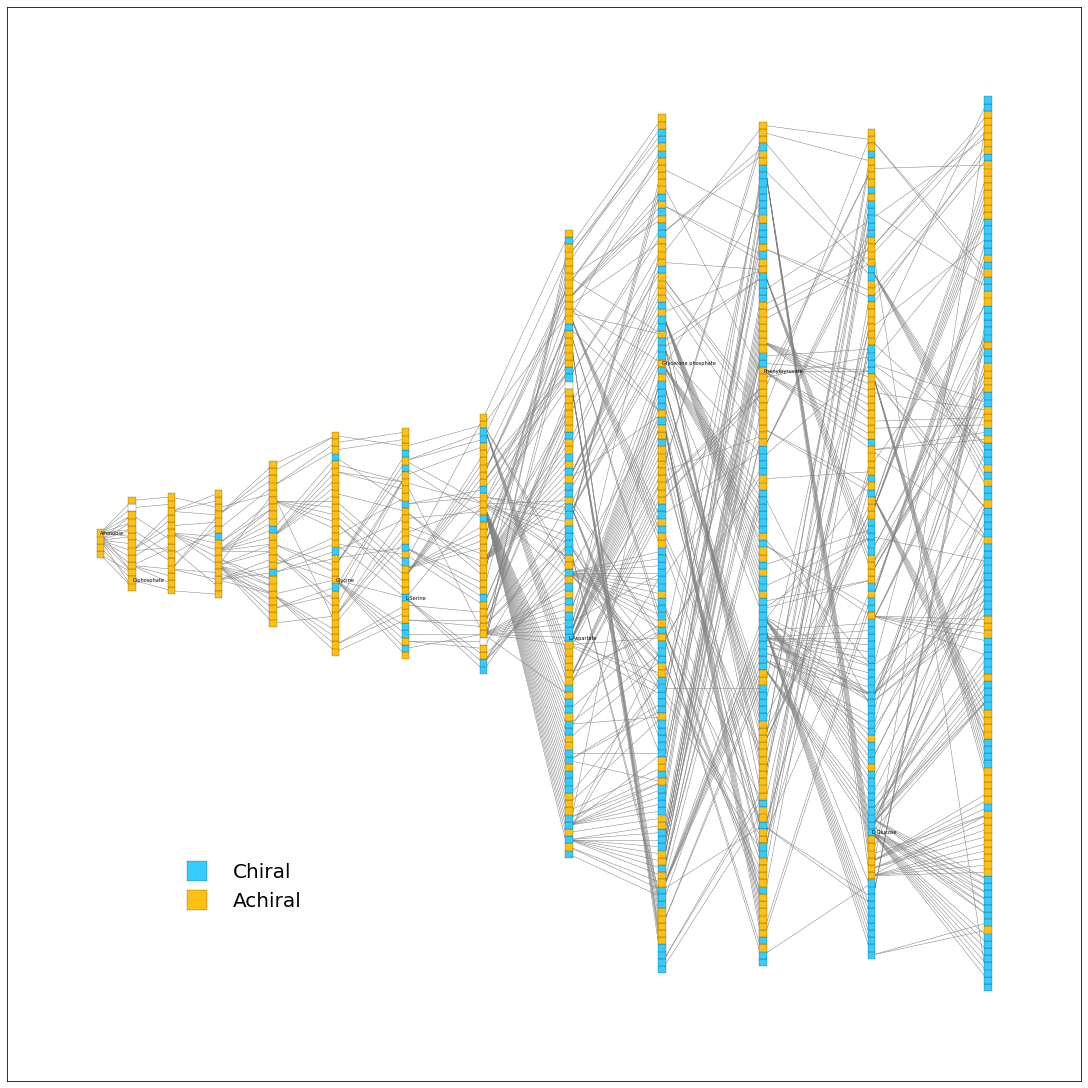

In [51]:
fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                  node_color=list(gna(G.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.5, arrows=False, labels=labels,
                  linewidths=0.2, node_size=55, node_shape='s', alpha=0.99,
                  with_labels=True, font_size=5, horizontalalignment='left')

plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
plt.savefig('fig3_expansion_'+show+'_edges_minimal_crossings_labeled_curated.svg', format='svg', facecolor='w', edgecolor='w')
plt.show()

In [69]:
minimal_crossings = pd.Series(pos).reset_index().reset_index().set_index('index')['level_0']

In [15]:
attributes['test'] = ((attributes['core_out_degree_chiral'])/(attributes['is_chiral']-0.5)).filter(like='C').sort_values()
attributes['minimal_crossings'] = minimal_crossings

sortby = ['minimal_crossings'] # minimal_crossings is_chiral test
show = 'precursor'

# need to re-order the highest layer for clarity - e.g., from most edges to the outermost nodes of previous layer to least, for chiral and achiral
# or based on the count of predecessors of the opposite chirality.

G = networks[show]

opposite_chirality_connections = dict()
for node in G.nodes(data=True):
    # identify chirality
    if node[1]['is_chiral']:
        assumption = 1
    else: assumption = -1
    # calculate extent to which node is "connected" to the opposite chirality (across predecessors and successors)
    neighbors = list(G.predecessors(node[0])) + list(G.successors(node[0]))
    #neighbors = list(G.successors(node[0]))
    opposite_chirality_connections[node[0]] = assumption * (attributes.loc[neighbors, 'is_chiral'] == node[1]['is_chiral']).sum()
attributes['opposite_chirality_connections'] = pd.Series(opposite_chirality_connections)

layers = [list(i) for i in attributes.loc[list(G.nodes)].sort_values(by=sortby, ascending=[False,False]).groupby(by='gen').groups.values()]
pos = get_multipartite_layout(edges=list(G.edges), layers=layers, reduce_edge_crossings=False) #difference

#pos = {i:j[::-1] for i,j in pos.items()}
#for n in pos.keys(): pos[n][1] = (pos[n][1]+0.1)**1.6
#fig, ax = plt.subplots(figsize=(25,8), layout='constrained')

# remove last layer
for i in layers[-1]: del pos[i]
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2


fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.6,0.6,0.6,0.5],
                  node_color=list(gna(G.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.5,
                  linewidths=0.2, node_size=42, node_shape='s', alpha=0.95,
                  with_labels=False, 
                  arrows=False, )
plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('test_fig3_expansion_'+show+'_edges.svg', format='svsg', facecolor='w', edgecolor='w')
plt.show()


NameError: name 'minimal_crossings' is not defined

In [110]:
attributes.loc[attributes['core_out_degree_chiral'].loc[pos.keys()].nlargest(20).index].to_csv('fig3_network_components/top_20_chiral_out_degree_nodes_core.csv')

,gen,n_chiral_centers,is_chiral,name,is_chiral_color,gen_color,infilled_degree,core_out_degree,precursor_out_degree,core_out_degree_chiral,precursor_out_degree_chiral,test,opposite_chirality_connections,minimal_crossings
C00001,0,0,False,H2O,#FFC012,#ffffff,387,165,2,90,0,-0.0,-2.0,1.0
C00002,13,4,True,ATP,#34CCFF,#282828,177,76,68,62,59,118.0,62.0,756.0
C00009,0,0,False,Orthophosphate,#FFC012,#ffffff,171,83,1,47,0,-0.0,-1.0,0.0
C00014,0,0,False,Ammonia,#FFC012,#ffffff,156,115,7,45,0,-0.0,-6.0,2.0
C00025,8,1,True,L-Glutamate,#34CCFF,#8d8d8d,73,49,16,39,12,24.0,13.0,172.0
C00008,13,4,True,ADP,#34CCFF,#282828,137,40,35,32,31,62.0,34.0,834.0
C00022,7,0,False,Pyruvate,#FFC012,#a0a0a0,104,68,31,31,17,-34.0,-17.0,156.0
C00024,12,5,True,Acetyl-CoA,#34CCFF,#404040,53,48,30,31,22,44.0,23.0,648.0
C00007,3,0,False,Oxygen,#FFC012,#e2e2e2,173,102,10,29,0,-0.0,-11.0,45.0
C00020,12,4,True,AMP,#34CCFF,#404040,59,36,16,27,15,30.0,17.0,658.0


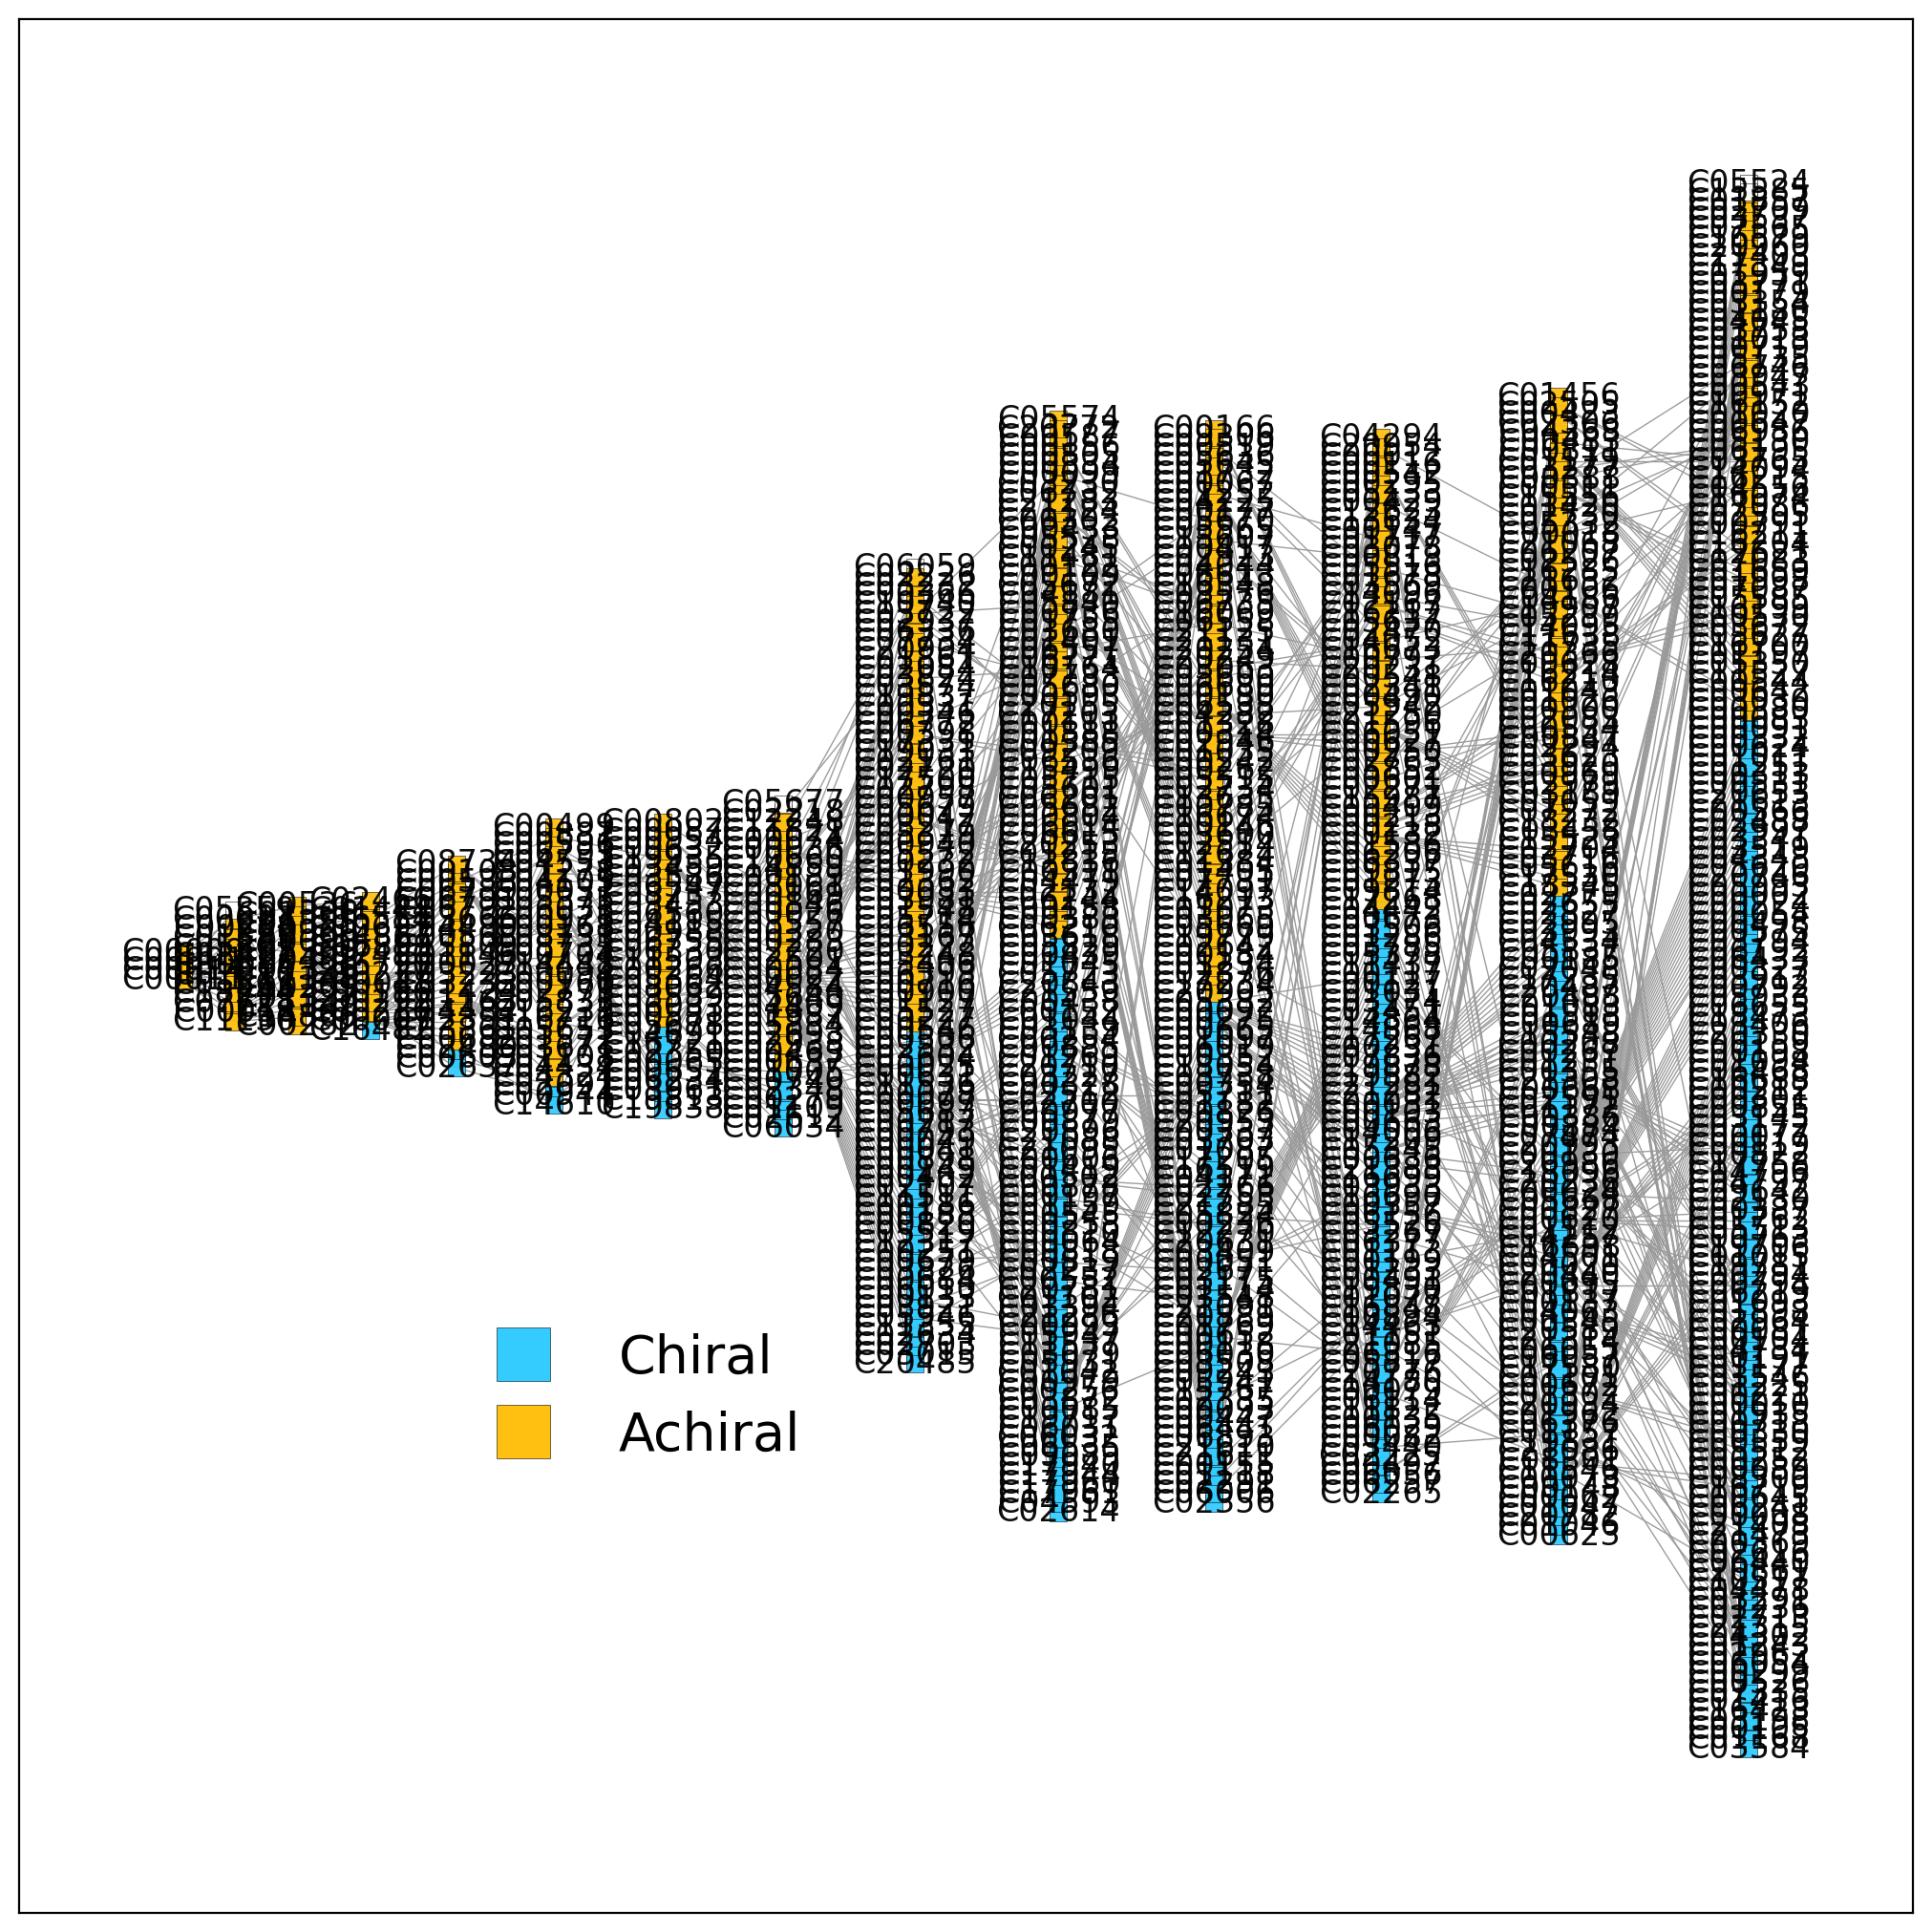

In [103]:
fig, ax = plt.subplots(figsize=(10,10), layout='constrained', dpi=200)
nx.draw_networkx(G.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.6,0.6,0.6,0.5],
                  node_color=list(gna(G.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.5, labels=
                  linewidths=0.2, node_size=42, node_shape='s', alpha=0.95,
                  with_labels=True, 
                  arrows=False)
plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('test_fig3_expansion_'+show+'_edges.svg', format='svsg', facecolor='w', edgecolor='w')
plt.show()